# New York City Taxi Trip Duration

**Dataset:** [Kaggle: NYC Taxi Trip Duration](https://www.kaggle.com/competitions/nyc-taxi-trip-duration/data)

**Goal:** predict how long (in seconds) a taxi trip in New York City will take, using information known at pickup: when and where the trip starts, where it ends, and a few details about the ride.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [3]:
train.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


# EDA

In [4]:
train.shape

(1458644, 11)

In [5]:
test.shape

(625134, 9)

In [6]:
train.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
       'trip_duration'],
      dtype='object')

In [7]:
test.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'],
      dtype='object')

The test set has two columns fewer than the training set:
- trip_duration, which is our target, the value we have to predict.
- dropoff_datetime, which would be of no use to us even if we had it. The trip duration is simply the dropoff time minus the pickup time, so this column would give away the answer. That is called data leakage, and it is why it is missing from the test set.

In [8]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1458644 entries, 0 to 1458643
Data columns (total 11 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   id                  1458644 non-null  object 
 1   vendor_id           1458644 non-null  int64  
 2   pickup_datetime     1458644 non-null  object 
 3   dropoff_datetime    1458644 non-null  object 
 4   passenger_count     1458644 non-null  int64  
 5   pickup_longitude    1458644 non-null  float64
 6   pickup_latitude     1458644 non-null  float64
 7   dropoff_longitude   1458644 non-null  float64
 8   dropoff_latitude    1458644 non-null  float64
 9   store_and_fwd_flag  1458644 non-null  object 
 10  trip_duration       1458644 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 122.4+ MB


pickup_datetime and dropoff_datetime are stored as object, so we first convert them to proper datetime format.

In [9]:
train['pickup_datetime'] = pd.to_datetime(train['pickup_datetime'])
train['dropoff_datetime'] = pd.to_datetime(train['dropoff_datetime'])

test['pickup_datetime'] = pd.to_datetime(test['pickup_datetime'])

In [10]:
train.describe()

,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration
count,1.458644e+06,1458644,1458644,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06,1.458644e+06
mean,1.534950e+00,2016-04-01 10:10:24.940037120,2016-04-01 10:26:24.432310528,1.664530e+00,-7.397349e+01,4.075092e+01,-7.397342e+01,4.075180e+01,9.594923e+02
min,1.000000e+00,2016-01-01 00:00:17,2016-01-01 00:03:31,0.000000e+00,-1.219333e+02,3.435970e+01,-1.219333e+02,3.218114e+01,1.000000e+00
25%,1.000000e+00,2016-02-17 16:46:04.249999872,2016-02-17 17:05:32.500000,1.000000e+00,-7.399187e+01,4.073735e+01,-7.399133e+01,4.073588e+01,3.970000e+02
50%,2.000000e+00,2016-04-01 17:19:40,2016-04-01 17:35:12,1.000000e+00,-7.398174e+01,4.075410e+01,-7.397975e+01,4.075452e+01,6.620000e+02
75%,2.000000e+00,2016-05-15 03:56:08.750000128,2016-05-15 04:10:51.750000128,2.000000e+00,-7.396733e+01,4.076836e+01,-7.396301e+01,4.076981e+01,1.075000e+03
max,2.000000e+00,2016-06-30 23:59:39,2016-07-01 23:02:03,9.000000e+00,-6.133553e+01,5.188108e+01,-6.133553e+01,4.392103e+01,3.526282e+06
std,4.987772e-01,NaN,NaN,1.314242e+00,7.090186e-02,3.288119e-02,7.064327e-02,3.589056e-02,5.237432e+03


A few things I noticed from the summary above: <br>
- passenger_count: the minimum is 0 and the maximum is 9, and neither is realistic for a taxi ride. We will clean this and keep only trips with 1 to 6 passengers. <br>
- trip_duration: the shortest trip is 1 second and the longest is about 3,526,282 seconds, which is roughly 980 hours or 40.8 days. That is not a normal taxi trip. We will keep only trips between 10 seconds and 3 hours. <br>
- Coordinates: we are also given longitude and latitude, so we can do more with them, such as calculating distance.

In [11]:
train.duplicated().sum()

np.int64(0)

# Target Column (trip_duration)

In [12]:
train['trip_duration'].describe()

count    1.458644e+06
mean     9.594923e+02
std      5.237432e+03
min      1.000000e+00
25%      3.970000e+02
50%      6.620000e+02
75%      1.075000e+03
max      3.526282e+06
Name: trip_duration, dtype: float64

Let's look for outliers in the target variable.

<Axes: xlabel='trip_duration'>

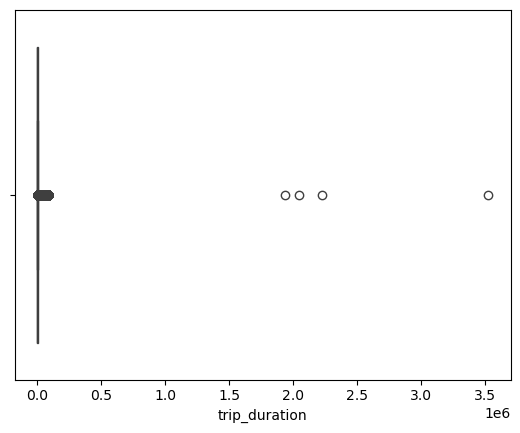

In [13]:
sns.boxplot(x = train['trip_duration'])

The boxplot shows a few extreme values that squash everything else into a thin line. Now let's count the trips that are too short or too long to be realistic.

In [14]:
print('trips less than 10 second:', (train['trip_duration']<10).sum())
print('trips over 24 hours:', (train['trip_duration']>86400).sum())

trips less than 10 second: 1984
trips over 24 hours: 4


Next, let's see how the target variable is distributed. First, a quick look at what skewness tells us.

### What skewness shows

Skewness measures how lopsided a distribution is: is the data balanced around its average, or does it have a long tail on one side?

- **Skew near 0:** symmetric, like a bell curve. Values are balanced on both sides of the mean.
- **Positive skew (right-skewed):** most values are small, but a few very large ones stretch the right tail. Salaries and house prices are common examples.
- **Negative skew (left-skewed):** most values are large, with a few very small ones dragging the left tail.

As a rough guide, a skew between -0.5 and 0.5 is fairly symmetric, between 0.5 and 1 (or -0.5 and -1) is moderately skewed, and beyond 1 (or -1) is highly skewed.

In [15]:
train['trip_duration'].skew()

np.float64(343.16394359173614)

The skewness is huge (343). The target has a very long right tail because of the extreme trips. <br>
To fix this, we take the `log` of the duration, which makes the distribution much more bell-shaped.

In [16]:
train['log_duration'] = np.log1p(train['trip_duration'])
train['log_duration'].skew()

np.float64(-0.2901609237260047)

<Axes: xlabel='log_duration', ylabel='Count'>

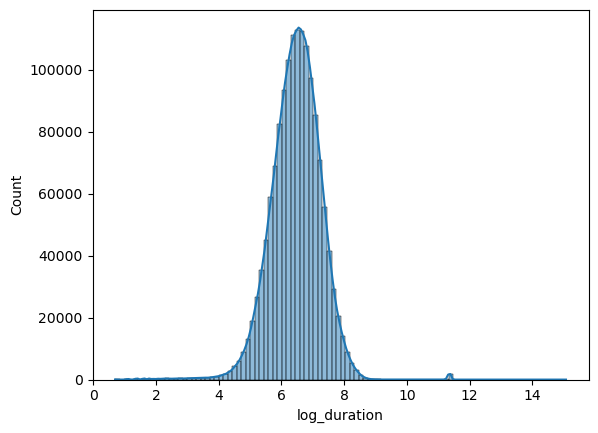

In [17]:
sns.histplot(train['log_duration'],bins=100, kde=True,)

After the log transform, the skewness is about -0.29, which is close to 0, and the histogram looks roughly bell-shaped.

We used `np.log1p(x)`, which is `log(1 + x)`. The plain log of 0 is undefined, so adding 1 stops a zero from breaking it, and it is also more accurate for very small values.

Keep in mind that the model will predict in log space, so at the end we must convert the predictions back to seconds:

`pred_seconds = np.expm1(pred_log)   # reverses log1p`

# Other Columns

Another issue is in the `passenger_count` column: the minimum is 0 and the maximum is 9, which looks wrong. The plot below shows how rare these values are.

<Axes: xlabel='passenger_count', ylabel='count'>

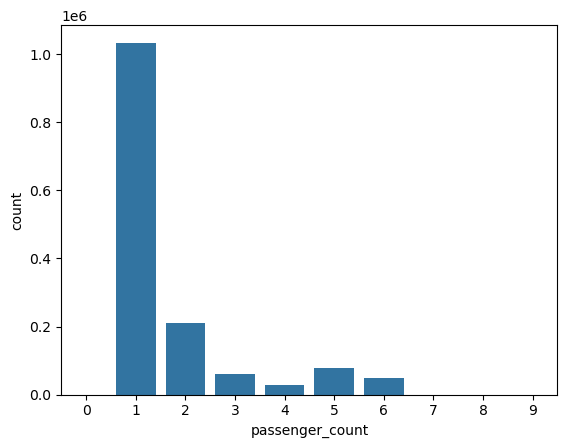

In [18]:
sns.countplot(x=train['passenger_count'])

<Axes: xlabel='vendor_id', ylabel='count'>

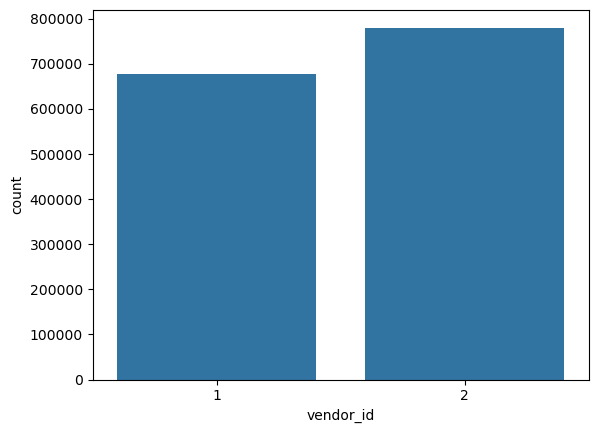

In [19]:
sns.countplot(x = train['vendor_id'])

We have the longitude and latitude of every trip, so we can plot them to check whether all trips are really inside New York.

For reference, New York City is at roughly 40.7127° N latitude and 74.0059° W longitude.

(40.6, 40.9)

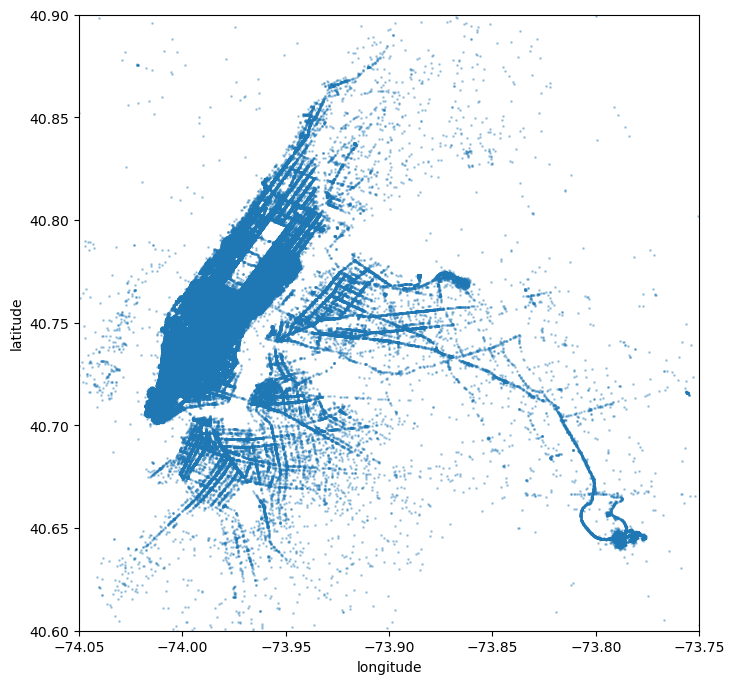

In [20]:
plt.figure(figsize=(8,8))
plt.scatter(train['pickup_longitude'], train['pickup_latitude'], s = 1, alpha = 0.3)
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.xlim(-74.05, -73.75)
plt.ylim(40.6, 40.9)

Here is the same map for the dropoff points. They are more spread out than the pickups.

(40.6, 40.9)

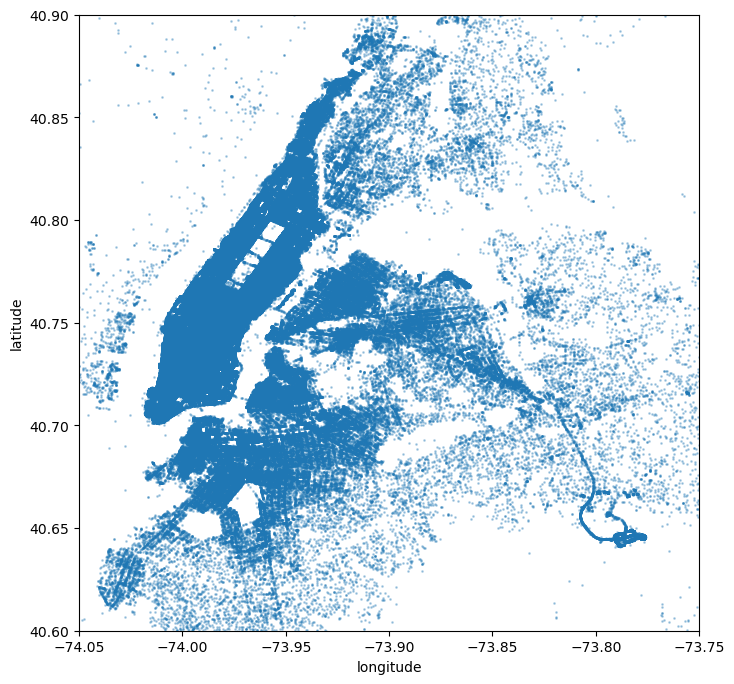

In [21]:
plt.figure(figsize = (8,8))
plt.scatter(train['dropoff_longitude'], train['dropoff_latitude'], s = 1, alpha = 0.3)
plt.xlabel('longitude')
plt.ylabel('latitude')
plt.xlim(-74.05, -73.75)
plt.ylim(40.6, 40.9)

Now let's count the trips where the pickup or dropoff falls outside a box around New York. These are most likely bad GPS readings.

In [22]:
box = (train['pickup_longitude'].between(-74.3, -73.7) & train['pickup_latitude'].between(40.5, 41.0) &
       train['dropoff_longitude'].between(-74.3, -73.7) & train['dropoff_latitude'].between(40.5, 41.0))
(~box).sum()

np.int64(998)

# Feature Engineering

Now let's create a distance feature, using the **Haversine formula**.

The Haversine formula calculates the shortest distance between two points on the surface of a sphere (the great-circle distance), using their latitudes and longitudes. Note that this is a straight-line distance, not the actual road distance.

In [23]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

Next, a small function that creates the same new features for both train and test, so they always match: pickup month, weekday (0 = Monday), hour, a weekend flag, and the distance.

In [24]:
def add_features(d):
    d['pickup_month'] = d['pickup_datetime'].dt.month
    d['pickup_weekday'] = d['pickup_datetime'].dt.dayofweek
    d['pickup_hour'] = d['pickup_datetime'].dt.hour
    d['is_weekend'] = (d['pickup_weekday'] >= 5).astype(int)
    d['distance_km'] = haversine(d['pickup_latitude'], d['pickup_longitude'],
                                 d['dropoff_latitude'], d['dropoff_longitude'])
    return d

train = add_features(train)
test = add_features(test)
train[['pickup_month', 'pickup_weekday', 'pickup_hour', 'is_weekend', 'distance_km']].head()

,pickup_month,pickup_weekday,pickup_hour,is_weekend,distance_km
0,3,0,17,0,1.498521
1,6,6,0,1,1.805507
2,1,1,11,0,6.385098
3,4,2,19,0,1.485498
4,3,5,13,1,1.188588


Distance statistics: the median trip is about 2 km, and some trips have a distance of 0 (the same pickup and dropoff point). The maximum is over 1,200 km, which is clearly a GPS error. The coordinate filter in the cleaning section will remove those.

In [25]:
train['distance_km'].describe()

count    1.458644e+06
mean     3.440864e+00
std      4.296538e+00
min      0.000000e+00
25%      1.231837e+00
50%      2.093717e+00
75%      3.875337e+00
max      1.240909e+03
Name: distance_km, dtype: float64

Number of trips by hour of day, weekday and month. Most trips start in the evening, and the fewest in the early morning hours. The weekday and month counts are fairly even.

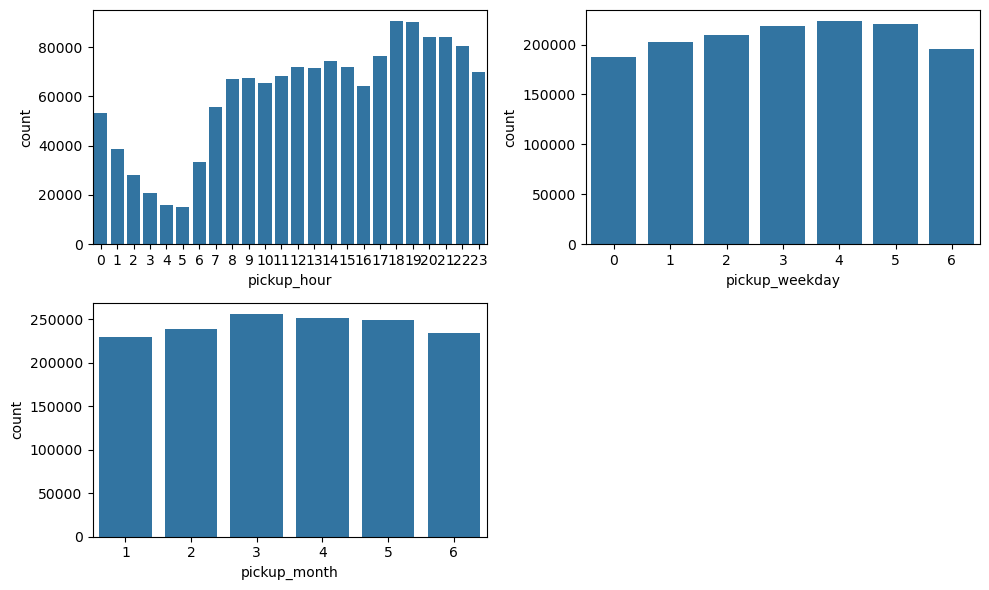

In [26]:
plt.figure(figsize = (10,6))
plt.subplot(2,2,1)
sns.countplot(x = train['pickup_hour'])
plt.subplot(2,2,2)
sns.countplot(x = train['pickup_weekday'])
plt.subplot(2,2,3)
sns.countplot(x = train['pickup_month'])

plt.tight_layout()

# Data Preprocessing and Cleaning

We keep only trips between 10 seconds and 3 hours. Anything outside this range is almost certainly a recording error.

In [27]:
train.shape

(1458644, 17)

In [28]:
train = train[(train['trip_duration']>10)&(train['trip_duration']<10800)]
train.shape

(1454366, 17)

In [29]:
train = train[train['passenger_count'].between(1, 6)]
train.shape

(1454326, 17)

In [30]:
train['speed_kmh'] = train['distance_km'] / (train['trip_duration'] / 3600)
train['speed_kmh'].describe()

count    1.454326e+06
mean     1.443118e+01
std      1.254057e+01
min      0.000000e+00
25%      9.149004e+00
50%      1.280914e+01
75%      1.785864e+01
max      6.877340e+03
Name: speed_kmh, dtype: float64

In [31]:
(train['speed_kmh'] > 100).sum()

np.int64(86)

Remove trips with impossible speeds (over 100 km/h).

In [32]:
train = train[train['speed_kmh'] <= 100]
train.shape

(1454240, 18)

Remove trips whose coordinates fall outside New York.

In [33]:
box = (train['pickup_longitude'].between(-74.3, -73.7) & train['pickup_latitude'].between(40.5, 41.0) &
       train['dropoff_longitude'].between(-74.3, -73.7) & train['dropoff_latitude'].between(40.5, 41.0))
train = train[box]
train.shape

(1453300, 18)

In [34]:
train.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration,log_duration,pickup_month,pickup_weekday,pickup_hour,is_weekend,distance_km,speed_kmh
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455,6.122493,3,0,17,0,1.498521,11.856428
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663,6.498282,6,6,0,1,1.805507,9.803659
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124,7.661527,1,1,11,0,6.385098,10.822201
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429,6.063785,4,2,19,0,1.485498,12.465721
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435,6.077642,3,5,13,1,1.188588,9.836594


Turn the text flag into numbers (N = 0, Y = 1), since models only understand numbers. With just two values, we don't need one-hot encoding.

In [35]:
train['store_and_fwd_flag'] = train['store_and_fwd_flag'].map({'N': 0, 'Y': 1})
test['store_and_fwd_flag'] = test['store_and_fwd_flag'].map({'N': 0, 'Y': 1})
train['store_and_fwd_flag'].value_counts()

store_and_fwd_flag
0    1445326
1       7974
Name: count, dtype: int64

Now we choose the columns the model will use and check how strongly each one is correlated with the target. `distance_km` is by far the strongest.

In [36]:
features = ['vendor_id', 'passenger_count', 'pickup_longitude', 'pickup_latitude',
            'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
            'pickup_month', 'pickup_weekday', 'pickup_hour', 'is_weekend', 'distance_km']
train[features + ['log_duration']].corr()['log_duration'].sort_values(ascending = False)

log_duration          1.000000
distance_km           0.654923
pickup_longitude      0.228011
dropoff_longitude     0.159810
pickup_month          0.049615
pickup_hour           0.039852
store_and_fwd_flag    0.019199
passenger_count       0.016447
vendor_id             0.008778
pickup_weekday       -0.030593
is_weekend           -0.057688
dropoff_latitude     -0.154564
pickup_latitude      -0.184353
Name: log_duration, dtype: float64

Final data:
- `X` is the training features.
- `y` is the target (the log of the duration).
- `X_test` is the test features.

We leave out `id` (it carries no information), the original date columns (we have already extracted what we need from `pickup_datetime`), and `dropoff_datetime` (it is not in the test set and would leak the answer).

# Model Training and Evaluation

We predict `log_duration`, not raw seconds, because trip durations are strongly right-skewed. We split the cleaned training data into a training set and a validation set. **Use `X_val` to make predictions for `y_val`**; the competition `test` dataset has no labels and must not be used to calculate validation metrics.


In [37]:
from sklearn.model_selection import train_test_split

features = ['vendor_id','passenger_count','pickup_longitude',
            'pickup_latitude','dropoff_longitude', 'dropoff_latitude',
            'store_and_fwd_flag', 'pickup_month','pickup_weekday', 
            'pickup_hour', 'is_weekend','distance_km']

X = train[features].copy()
y = train['log_duration'].copy()
X_competition_test = test[features].copy()

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)
print("Competition test features:", X_competition_test.shape)

Training features: (1162640, 12)
Validation features: (290660, 12)
Training target: (1162640,)
Validation target: (290660,)
Competition test features: (625134, 12)


## Evaluation metrics

- **MAE**: average absolute prediction error.
- **RMSE**: penalises larger errors more strongly than MAE.
- **R²**: compares the model with a baseline that predicts the mean target; closer to 1 is generally better.

The primary comparison below is on the log-transformed target, because that is what the models learn.


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def evaluate_regression(name, fitted_model, X_valid, y_valid):
    pred = fitted_model.predict(X_valid)
    return {
        "Model": name,
        "MAE (log seconds)": mean_absolute_error(y_valid, pred),
        "RMSE (log seconds)": np.sqrt(mean_squared_error(y_valid, pred)),
        "R² (log target)": r2_score(y_valid, pred)
    }


## Histogram-based Gradient Boosting

`HistGradientBoostingRegressor` bins numeric values into histograms, which makes it more practical for larger datasets. It can learn non-linear patterns and interactions between features.


In [47]:
from sklearn.ensemble import HistGradientBoostingRegressor

hist_gradient_boosting_model = HistGradientBoostingRegressor(learning_rate=0.05,
    max_iter=300,max_leaf_nodes=31,l2_regularization=1.0,early_stopping=True,random_state=42)

hist_gradient_boosting_model.fit(X_train, y_train)

results.append(evaluate_regression("Histogram Gradient Boosting",
        hist_gradient_boosting_model,X_val,y_val))

In [48]:
results_df = pd.DataFrame(results).sort_values("RMSE (log seconds)")
results_df.round(4)

,Model,MAE (log seconds),RMSE (log seconds),R² (log target)
2,Histogram Gradient Boosting,0.2605,0.3637,0.7662
4,Histogram Gradient Boosting,0.2605,0.3637,0.7662
5,Histogram Gradient Boosting,0.2605,0.3637,0.7662
1,Gradient Boosting (sample),0.2966,0.4022,0.7140
3,Gradient Boosting (sample),0.2966,0.4022,0.7140
0,Linear Regression,0.4218,0.5519,0.4615
